# Figure 2 demo: collagen IV, intestine Image 1

**Estimated runtime: 3–5 minutes with an RTX 4070 SUPER or similar CUDA
GPU and eight CPU threads**, excluding package installation and the first
dataset download. CPU-only training takes longer. **Measured runtime: 3 min 43 s** (RTX 4070 SUPER, eight CPU threads, cached dataset). All 14 code cells completed, including the full 200-epoch CNN and 200-epoch GraphMAE fits.

Fit the intensity baselines, one contrastive CNN, and four spatial methods
from the same image. **Seed 0 throughout; one CNN fit shared by every
downstream method.** The settings are the frozen selections from the
paper's matched 12-setting comparison (Figure 2c).

This is a fresh-fit demonstration. The paper reports three-seed results;
exact saved results and figure replotting are in the reproducibility
repository. No parameter search or multipanel figure assembly is performed.

Keep `fig2_demo_helpers.py` beside this notebook.
The helper contains only the selected CNN and the repeated patch-map plot.


## Setup

In Colab, keep runtime version **Latest** and select a GPU under
**Runtime > Change runtime type**. Run setup, restart when requested,
then run all cells.
Locally, install `fig2_demo_requirements.txt` in
Python 3.11/3.12/3.13 and keep the helper beside the notebook.


In [1]:
import importlib.util
try:
    in_colab = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    in_colab = False

if in_colab:
    from pathlib import Path
    from urllib.request import urlretrieve
    if not Path("colab_setup.py").exists():
        urlretrieve("https://raw.githubusercontent.com/moeghaf/mantpy_reproducibility/main/notebooks/demos/colab_setup.py", "colab_setup.py")
    from colab_setup import prepare_colab
    prepare_colab("fig2")


In [2]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad
import torch
import mantpy as mt
from scipy import sparse
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from threadpoolctl import threadpool_limits
from fig2_demo_helpers import fit_shared_cnn, plot_patch_labels

SEED = 0
K = 5
PATCH_SIZE = 32
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(8)
threadpool_limits(limits=8)
print(f"Seed {SEED}; device: {DEVICE}")


<python-environment>/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Seed 0; device: cuda


## 1. Load and visualise Image 1

The public Mantpy loader downloads and caches the raw collagen-IV image
and the original manual 32-pixel tile reference. The reference is used
only in the final evaluation.


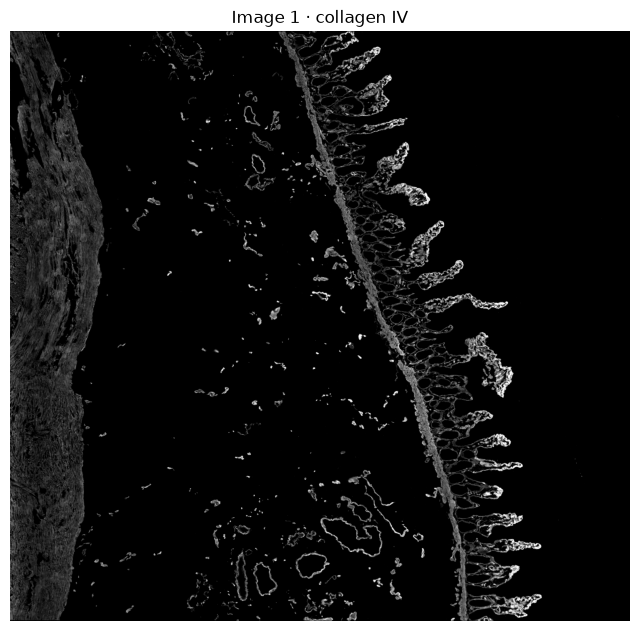

In [3]:
bundle = mt.datasets.coliv_intestine(cache_dir=Path("data"))
image = np.asarray(bundle.image)
PIXEL_UM = float(bundle.pixel_size_um)

CLIP = float(np.percentile(image[image > 0], 99))
assert CLIP == 9928.0
scaled = np.clip(image.astype(np.float32), 0, CLIP) / CLIP

plt.figure(figsize=(8, 8))
plt.imshow(scaled[::4, ::4], cmap="gray", vmin=0, vmax=1)
plt.title("Image 1 · collagen IV")
plt.axis("off")
plt.show()


## 2. Shared preprocessing

Clip at the 99th percentile of positive pixels and scale to [0, 1].
Use non-overlapping 32 × 32 patches and the paper's locked foreground
thresholds. Every patch method uses the same 13,376 retained patches.
Coordinates are converted from pixels to micrometres for spatial methods.


In [4]:
patches = mt.pp.image_ecm_patches(
    image,
    channel_names=["ColIV"],
    patch_size=PATCH_SIZE,
    clip_percentile=99,
    pixel_thresholds=[0.34971654415130615],
    patch_thresholds=[0.13433519005775452],
    feature_families=("summary",),
    sample_id="Image1",
    random_state=SEED,
)
assert patches.n_obs == 13376
windows = patches.obsm["image_patches"]
patches.obsm["spatial"] = patches.obsm["spatial"].astype(np.float64) * PIXEL_UM
labels = {}
print(f"{patches.n_obs:,} patches; windows: {windows.shape}; {PIXEL_UM:g} µm/pixel")


<python-environment>/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
<python-environment>/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


13,376 patches; windows: (13376, 1, 32, 32); 0.37744 µm/pixel


## 3. Pixel K-means

Fit five intensity clusters to the paper's seeded sample of 2,000,000
pixels, including background. Predict the full image in chunks.


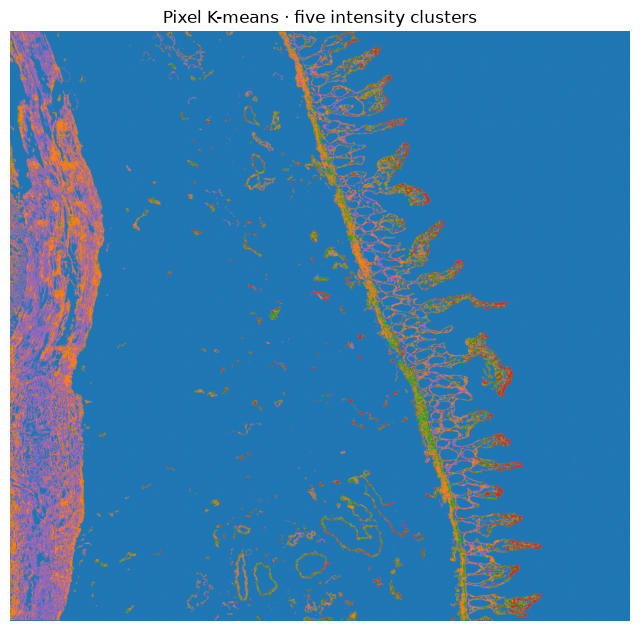

In [5]:
sample_indices = np.sort(
    np.random.default_rng(SEED).choice(scaled.size, 2_000_000, replace=False)
)
pixel_model = KMeans(n_clusters=K, n_init=1, random_state=SEED)
pixel_model.fit(scaled.ravel()[sample_indices, None])
pixel_labels = np.empty(image.shape, dtype=np.uint8)
for start in range(0, image.shape[0], 512):
    block = scaled[start:start + 512]
    pixel_labels[start:start + 512] = pixel_model.predict(
        block.reshape(-1, 1)
    ).reshape(block.shape)

plt.figure(figsize=(8, 8))
plt.imshow(pixel_labels[::4, ::4], cmap="tab10", vmin=0, vmax=9)
plt.title("Pixel K-means · five intensity clusters")
plt.axis("off")
plt.show()


## 4. Patch-mean K-means

Cluster the mean scaled collagen-IV intensity of each retained patch.


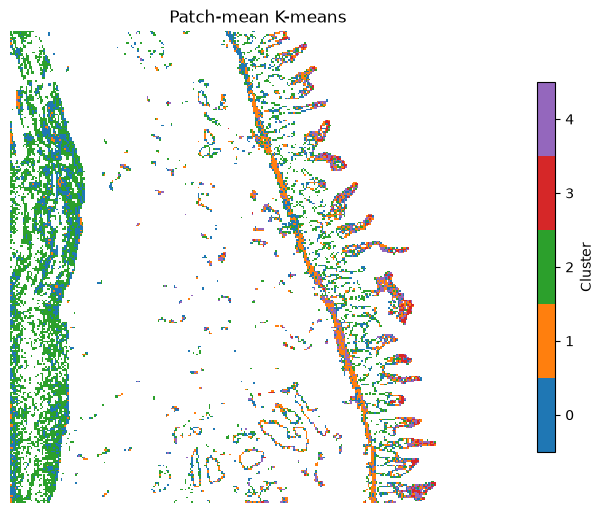

In [6]:
patch_mean = windows.mean(axis=(1, 2, 3)).reshape(-1, 1)
labels["Patch-mean K-means"] = KMeans(
    n_clusters=K, n_init=1, random_state=SEED
).fit_predict(patch_mean)
plot_patch_labels(patches, labels["Patch-mean K-means"], "Patch-mean K-means")


## 5. Train the shared CNN once

Selected architecture: three stride-2 convolution blocks (32, 64, 128
channels), BatchNorm and ReLU, 1 × 1 average pooling, 96 latent features,
and a 64-feature projection head. Train with the paper's SimCLR
augmentation, temperature 0.2, AdamW and cosine learning-rate schedule.
Standardise the 96 latent features once across all retained patches.

Mantpy 1.0.2's public `PatchEncoder` has a fixed architecture. The small
companion helper exposes this selected architecture using public PyTorch
APIs; its architecture and training recipe match the shared comparison.


Shared CNN: 100%|██████████| 200/200 [00:48<00:00,  4.10it/s, loss=3.501]


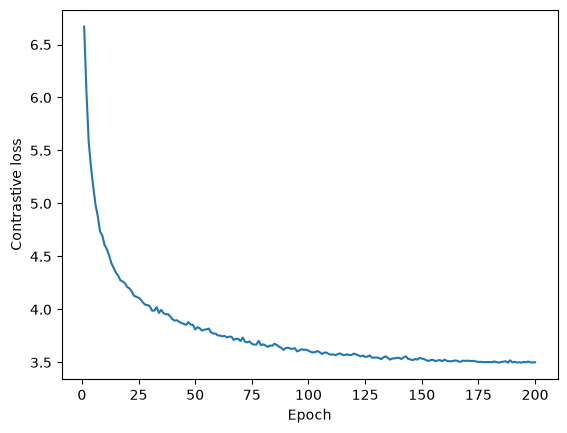

In [7]:
cnn, cnn_features, cnn_loss = fit_shared_cnn(
    windows,
    seed=SEED,
    blocks=3,
    width=32,
    latent_dim=96,
    projection_dim=64,
    temperature=0.2,
    epochs=200,
    batch_size=1024,
    lr=1e-3,
    weight_decay=1e-5,
    device=DEVICE,
)
patches.obsm["X_cnn"] = cnn_features
plt.plot(np.arange(1, len(cnn_loss) + 1), cnn_loss)
plt.xlabel("Epoch")
plt.ylabel("Contrastive loss")
plt.show()


## 6. CNN K-means

All following methods start from this same standardised CNN matrix.
K-means uses ten initialisations with the single seed 0.


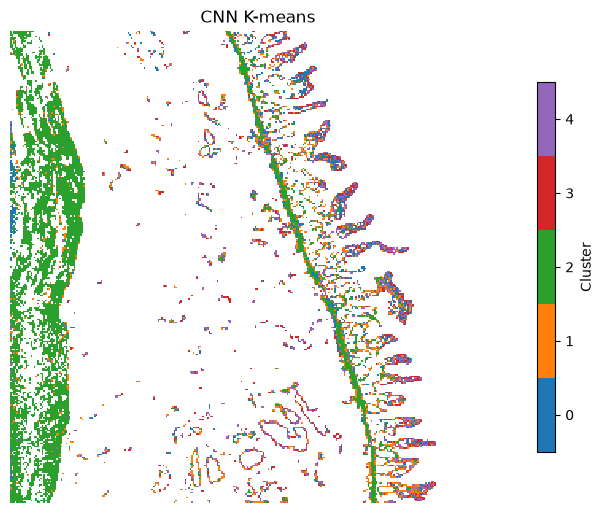

In [8]:
labels["CNN K-means"] = KMeans(
    n_clusters=K, n_init=10, random_state=SEED
).fit_predict(cnn_features)
plot_patch_labels(patches, labels["CNN K-means"], "CNN K-means")


## 7. GraphMAE

Selected graph: symmetrised 240-nearest-neighbour graph, foreground
continuity threshold 0.25 with six samples. Selected model: two GIN
layers, width 128, mask ratio 0.75, LayerNorm, jumping knowledge,
re-masking decoder and scaled-cosine reconstruction loss.


GraphMAE: 100%|██████████| 200/200 [00:20<00:00,  9.99epoch/s, loss=0.3537]


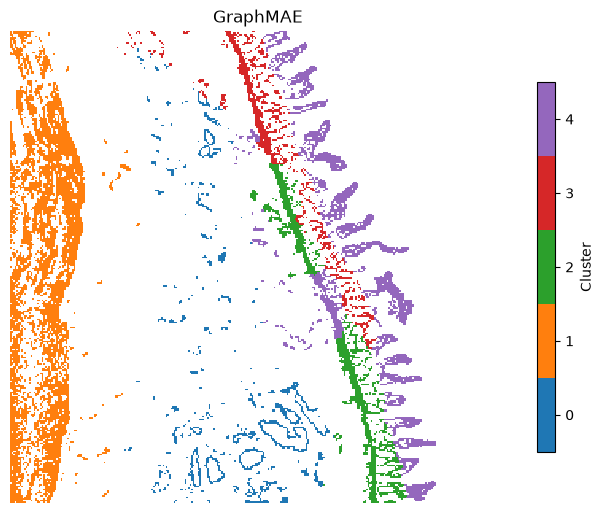

In [9]:
mt.gr.build_patch_graph(
    patches, k=240, continuity_thresh=0.25, continuity_samples=6,
    key_added="graphmae",
)
graph = mt.gr.to_pyg(
    patches, graph_key="graphmae", node_feature_key="X_cnn",
    include_edge_features=False,
)
graphmae = mt.nn.GraphMAE(
    hidden_dim=128, n_layers=2, encoder="gin",
    decoder="graphmae_remask", norm="layernorm",
    mask_ratio=0.75, mitigation="jk",
)
graphmae.train(
    graph, max_epochs=200, lr=1e-3, weight_decay=1e-4,
    recon_loss="scaled_cosine", standardize=False,
    rng=SEED, accelerator=DEVICE,
)
patches.obsm["X_graphmae"] = graphmae.get_node_latent()
labels["GraphMAE"] = KMeans(
    n_clusters=K, n_init=10, random_state=SEED
).fit_predict(patches.obsm["X_graphmae"])
plot_patch_labels(patches, labels["GraphMAE"], "GraphMAE")


## 8. UTAG

Apply native UTAG mean aggregation with the frozen 232.3265 µm radius,
then PCA to ten components and five-cluster K-means.


Applying UTAG Algorithm...
INFO     Creating graph using `None` transform and `1` libraries.                                                  


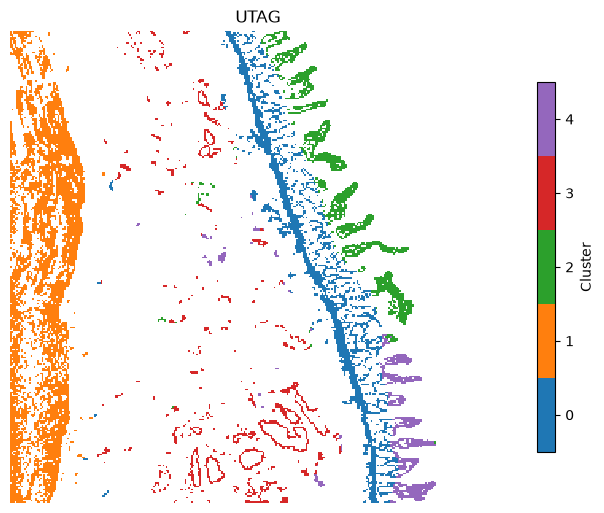

In [10]:
from utag import utag

utag_input = ad.AnnData(X=cnn_features.copy(), obs=patches.obs.copy())
utag_input.obsm["spatial"] = patches.obsm["spatial"].copy()
utag_result = utag(
    utag_input, slide_key=None, max_dist=232.3265075275914,
    normalization_mode="l1_norm", apply_clustering=False, parallel=False,
)
assert utag_result.obs_names.equals(patches.obs_names)
utag_features = utag_result.X
if sparse.issparse(utag_features):
    utag_features = utag_features.toarray()
utag_pca = PCA(n_components=10, random_state=SEED).fit_transform(
    np.asarray(utag_features, dtype=np.float32)
)
labels["UTAG"] = KMeans(
    n_clusters=K, n_init=10, random_state=SEED
).fit_predict(utag_pca)
plot_patch_labels(patches, labels["UTAG"], "UTAG")


## 9. BANKSY

Use native scaled-Gaussian weighting, 240 neighbours, λ = 0.4 and
azimuthal order 1. Reduce the BANKSY matrix to 20 PCs, then use K-means.



Median distance to closest cell = 12.078079999999773

---- Ran median_dist_to_nearest_neighbour in 0.05 s ----

---- Ran generate_spatial_distance_graph in 0.79 s ----

---- Ran row_normalize in 0.05 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 1.21 s ----

---- Ran generate_spatial_distance_graph in 1.46 s ----

---- Ran theta_from_spatial_graph in 0.47 s ----

---- Ran row_normalize in 0.04 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 2.62 s ----

Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 3210240 stored elements and shape (13376, 13376)>, 1: <Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 6420480 stored elements and shape (13376, 13376)>}}

Nbr matrix | Mean: 0.0 | Std: 0.45
Size of Nbr | Shape: (13376, 96)
Top 3 entries of Nbr Mat:

[[ 0.20992208  0.33567338 -0.72231801]
 [ 0.20673092  0.33513797 -0.73098028]
 [ 0.21608798  0.34370562 -0.73870716]]

AGF matrix | Me

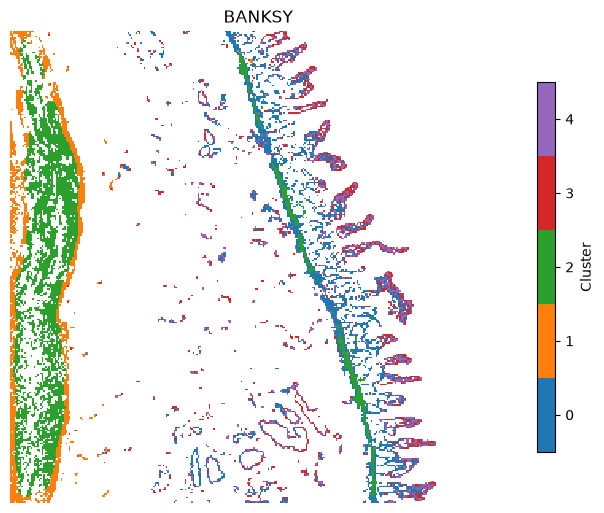

In [11]:
from banksy.initialize_banksy import initialize_banksy
from banksy.embed_banksy import generate_banksy_matrix

banksy_input = ad.AnnData(X=cnn_features.copy(), obs=patches.obs.copy())
banksy_input.obsm["spatial"] = patches.obsm["spatial"].copy()
banksy_input.obs[["x", "y"]] = banksy_input.obsm["spatial"]
banksy_dict = initialize_banksy(
    banksy_input, coord_keys=("x", "y", "spatial"),
    num_neighbours=240, nbr_weight_decay="scaled_gaussian", max_m=1,
    plt_edge_hist=False, plt_nbr_weights=False,
    plt_agf_angles=False, plt_theta=False,
)
banksy_dict, _ = generate_banksy_matrix(
    banksy_input, banksy_dict, lambda_list=[0.4], max_m=1, verbose=False,
)
banksy_features = banksy_dict["scaled_gaussian"][0.4]["adata"].X
assert banksy_dict["scaled_gaussian"][0.4]["adata"].obs_names.equals(patches.obs_names)
if sparse.issparse(banksy_features):
    banksy_features = banksy_features.toarray()
banksy_pca = PCA(n_components=20, random_state=SEED).fit_transform(
    np.asarray(banksy_features, dtype=np.float32)
)
labels["BANKSY"] = KMeans(
    n_clusters=K, n_init=10, random_state=SEED
).fit_predict(banksy_pca)
plot_patch_labels(patches, labels["BANKSY"], "BANKSY")


## 10. CellCharter

Aggregate the shared CNN features over three hops of the same
foreground-aware 120-neighbour graph, then fit native five-component
CellCharter clustering. No additional PCA or encoder is fitted.
CellCharter runs on CPU, as in the paper's native comparator environment.


W1029 18:38:59.157000 65344 torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
100%|██████████| 4/4 [00:01<00:00,  2.10it/s]
GPU available: True (cuda), used: False
TPU available: False, using: 0 TPU cores
<python-environment>/site-packages/pytorch_lightning/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
GPU available: True (cuda), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
GPU available: True (cuda), used: False
TPU availa

<python-environment>/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" 
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

GPU available: True (cuda), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


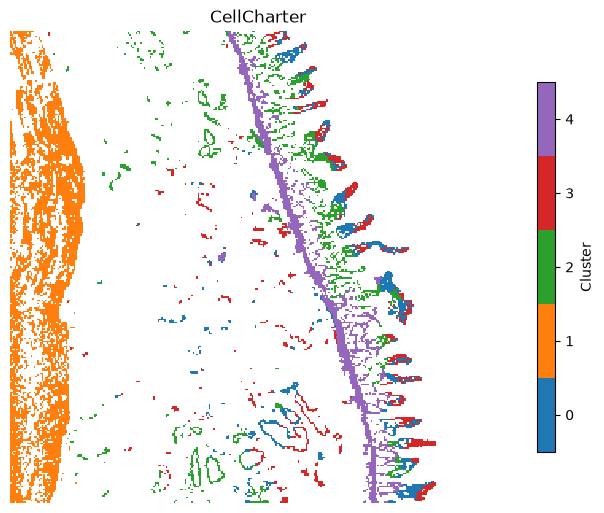

In [12]:
import cellcharter as cc

mt.gr.build_patch_graph(
    patches, k=120, continuity_thresh=0.25, continuity_samples=6,
    key_added="cellcharter",
)
patches.obs["sample_id"] = pd.Categorical(patches.obs["sample_id"])
cc.gr.aggregate_neighbors(
    patches, n_layers=3, aggregations="mean", use_rep="X_cnn",
    connectivity_key="cellcharter_connectivities", sample_key="sample_id",
)
torch.manual_seed(SEED)
np.random.seed(SEED)
cellcharter = cc.tl.Cluster(
    n_clusters=K, random_state=SEED, trainer_params={"accelerator": "cpu"}
)
cellcharter.fit(patches)
labels["CellCharter"] = np.asarray(cellcharter.predict(patches), dtype=int)
plot_patch_labels(patches, labels["CellCharter"], "CellCharter")


## 11. Evaluate on the common annotated foreground

Compare every method to the original manual tile labels. Patch labels
are expanded over their 1,024 native pixels. Pixel K-means is scored
pixel by pixel on exactly those same tiles, without a majority vote.
Cluster numbers and colours are arbitrary; ARI is invariant to their
names. A fresh single-seed fit can differ from the paper's mean.


In [13]:
reference = bundle.reference.reset_index().set_index("patch_id")
reference = reference.reindex(patches.obs_names)
annotated = reference["layer"].notna().to_numpy()
truth = reference.loc[annotated, "layer"].to_numpy(dtype=int)
truth_pixels = np.repeat(truth, PATCH_SIZE ** 2)
assert all(len(partition) == patches.n_obs and len(np.unique(partition)) == K for partition in labels.values())
pixel_predictions = np.concatenate([
    pixel_labels[
        row * PATCH_SIZE:(row + 1) * PATCH_SIZE,
        col * PATCH_SIZE:(col + 1) * PATCH_SIZE,
    ].ravel()
    for row, col in patches.obs.loc[annotated, ["grid_y", "grid_x"]].itertuples(index=False, name=None)
])
scores = {"Pixel K-means": adjusted_rand_score(truth_pixels, pixel_predictions)}
for method, partition in labels.items():
    scores[method] = adjusted_rand_score(
        truth_pixels, np.repeat(partition[annotated], PATCH_SIZE ** 2)
    )
pd.DataFrame.from_dict(scores, orient="index", columns=["ARI · seed 0"]).round(4)


,ARI · seed 0
Pixel K-means,0.1963
Patch-mean K-means,0.2294
CNN K-means,0.4661
GraphMAE,0.8399
UTAG,0.8432
BANKSY,0.4082
CellCharter,0.7918


## Save this run

Save the patch features, graph metadata, method labels and scores for
inspection. These are outputs of this demo run.


In [14]:
result_dir = Path("demo_results")
result_dir.mkdir(exist_ok=True)
for method, partition in labels.items():
    patches.obs[method] = pd.Categorical(partition)
patches.uns["demo_seed"] = SEED
patches.write_h5ad(result_dir / "image1_demo.h5ad")
pd.Series(scores, name="ARI_seed0").to_csv(result_dir / "scores.csv")


### Data and APIs

[Mantpy](https://github.com/moeghaf/Mantpy) ·
[public dataset](https://doi.org/10.5281/zenodo.21538382) ·
[UTAG](https://github.com/ElementoLab/utag) ·
[BANKSY](https://github.com/prabhakarlab/Banksy_py) ·
[CellCharter](https://cellcharter.readthedocs.io/en/stable/)
